# Data prep and EDA

Labelled Prudential applications only. `Response` is the 8-class underwriting target. The hold-out used by the models is a stratified 80/20 split of this file.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "prep.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from prep import (
    DATA_DIR,
    DROP_SPARSE,
    build_preprocessor,
    fit_save_artefacts,
    high_low_risk,
    load_labelled,
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)


## Load


In [2]:

df = load_labelled(DATA_DIR)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
print("Duplicate Ids:", int(df["Id"].duplicated().sum()))
print(df.dtypes.value_counts())
df.head(3)


59,381 rows x 128 columns
Duplicate Ids: 0
int64      109
float64     18
str          1
Name: count, dtype: int64


,Id,Product_Info_1,Product_Info_2,Product_Info_3,Product_Info_4,Product_Info_5,Product_Info_6,Product_Info_7,Ins_Age,Ht,Wt,BMI,Employment_Info_1,Employment_Info_2,Employment_Info_3,Employment_Info_4,Employment_Info_5,Employment_Info_6,InsuredInfo_1,InsuredInfo_2,InsuredInfo_3,InsuredInfo_4,InsuredInfo_5,InsuredInfo_6,InsuredInfo_7,...,Medical_Keyword_25,Medical_Keyword_26,Medical_Keyword_27,Medical_Keyword_28,Medical_Keyword_29,Medical_Keyword_30,Medical_Keyword_31,Medical_Keyword_32,Medical_Keyword_33,Medical_Keyword_34,Medical_Keyword_35,Medical_Keyword_36,Medical_Keyword_37,Medical_Keyword_38,Medical_Keyword_39,Medical_Keyword_40,Medical_Keyword_41,Medical_Keyword_42,Medical_Keyword_43,Medical_Keyword_44,Medical_Keyword_45,Medical_Keyword_46,Medical_Keyword_47,Medical_Keyword_48,Response
0,2,1,D3,10,0.076923,2,1,1,0.641791,0.581818,0.148536,0.323008,0.028,12,1,0.0,3,NaN,1,2,6,3,1,2,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8
1,5,1,A1,26,0.076923,2,3,1,0.059701,0.600000,0.131799,0.272288,0.000,1,3,0.0,2,0.0018,1,2,6,3,1,2,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4
2,6,1,E1,26,0.076923,2,3,1,0.029851,0.745455,0.288703,0.428780,0.030,9,1,0.0,2,0.0300,1,2,8,3,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8


In [3]:

groups = {
    "Product_Info": [c for c in df.columns if c.startswith("Product_Info_")],
    "Body/Age": ["Ins_Age", "Ht", "Wt", "BMI"],
    "Employment_Info": [c for c in df.columns if c.startswith("Employment_Info_")],
    "InsuredInfo": [c for c in df.columns if c.startswith("InsuredInfo_")],
    "Insurance_History": [c for c in df.columns if c.startswith("Insurance_History_")],
    "Family_Hist": [c for c in df.columns if c.startswith("Family_Hist_")],
    "Medical_History": [c for c in df.columns if c.startswith("Medical_History_")],
    "Medical_Keyword": [c for c in df.columns if c.startswith("Medical_Keyword_")],
}
for name, cols in groups.items():
    print(f"{name:20s} {len(cols):3d} columns")
print("Insurance_History_6 is not in the file.")
print("Product_Info_2 levels:", df["Product_Info_2"].nunique())


Product_Info           7 columns
Body/Age               4 columns
Employment_Info        6 columns
InsuredInfo            7 columns
Insurance_History      8 columns
Family_Hist            5 columns
Medical_History       41 columns
Medical_Keyword       48 columns
Insurance_History_6 is not in the file.
Product_Info_2 levels: 19


Columns with missing values: 13


,fraction_missing
Medical_History_10,0.990620
Medical_History_32,0.981358
Medical_History_24,0.935990
Medical_History_15,0.751015
Family_Hist_5,0.704114
Family_Hist_3,0.576632
Family_Hist_2,0.482579
Insurance_History_5,0.427679
Family_Hist_4,0.323066
Employment_Info_6,0.182786


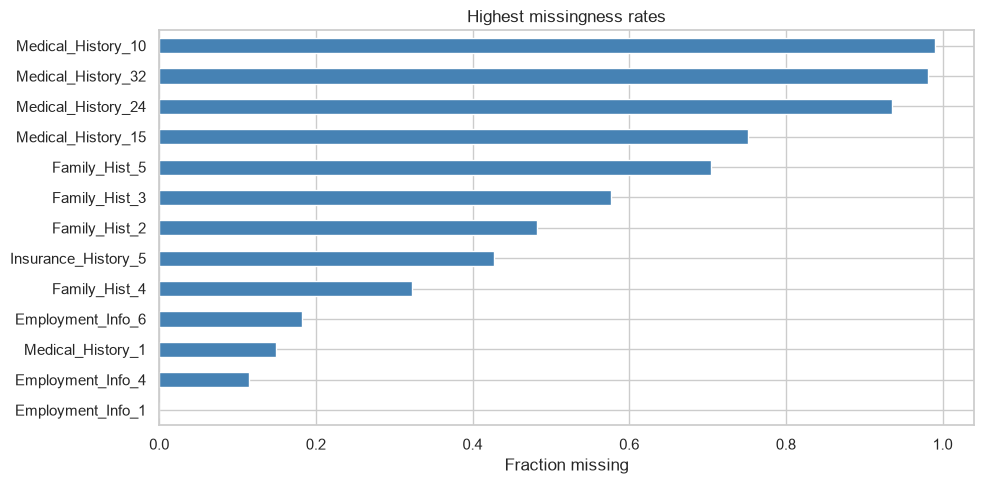

In [4]:

miss = df.isna().mean().sort_values(ascending=False)
miss_pos = miss[miss > 0]
print(f"Columns with missing values: {len(miss_pos)}")
display(miss_pos.head(20).to_frame("fraction_missing"))

fig, ax = plt.subplots(figsize=(10, 5))
miss_pos.head(20).sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Fraction missing")
ax.set_title("Highest missingness rates")
plt.tight_layout()
plt.show()


## Target


,count,proportion
Response,,
1,6207,0.104528
2,6552,0.110338
3,1013,0.017059
4,1428,0.024048
5,5432,0.091477
6,11233,0.189168
7,8027,0.135178
8,19489,0.328203


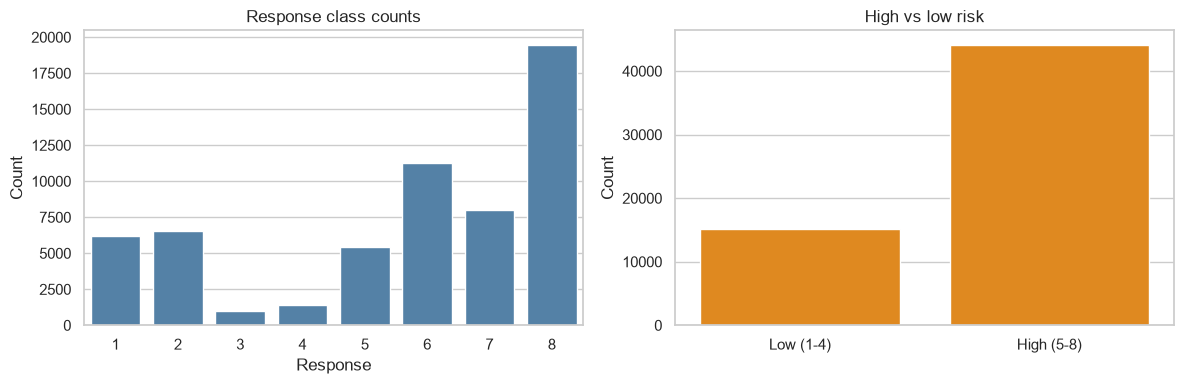

High-risk share: 74.4%


In [5]:

vc = df["Response"].value_counts().sort_index()
summary = pd.DataFrame({
    "count": vc,
    "proportion": df["Response"].value_counts(normalize=True).sort_index(),
})
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=vc.index.astype(str), y=vc.values, ax=axes[0], color="steelblue")
axes[0].set_title("Response class counts")
axes[0].set_xlabel("Response")
axes[0].set_ylabel("Count")

y_bin = high_low_risk(df["Response"])
bin_counts = pd.Series(y_bin).value_counts().sort_index()
sns.barplot(x=["Low (1-4)", "High (5-8)"], y=bin_counts.values, ax=axes[1], color="darkorange")
axes[1].set_title("High vs low risk")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()
print(f"High-risk share: {y_bin.mean():.1%}")


## A few views that show up again in the explanations


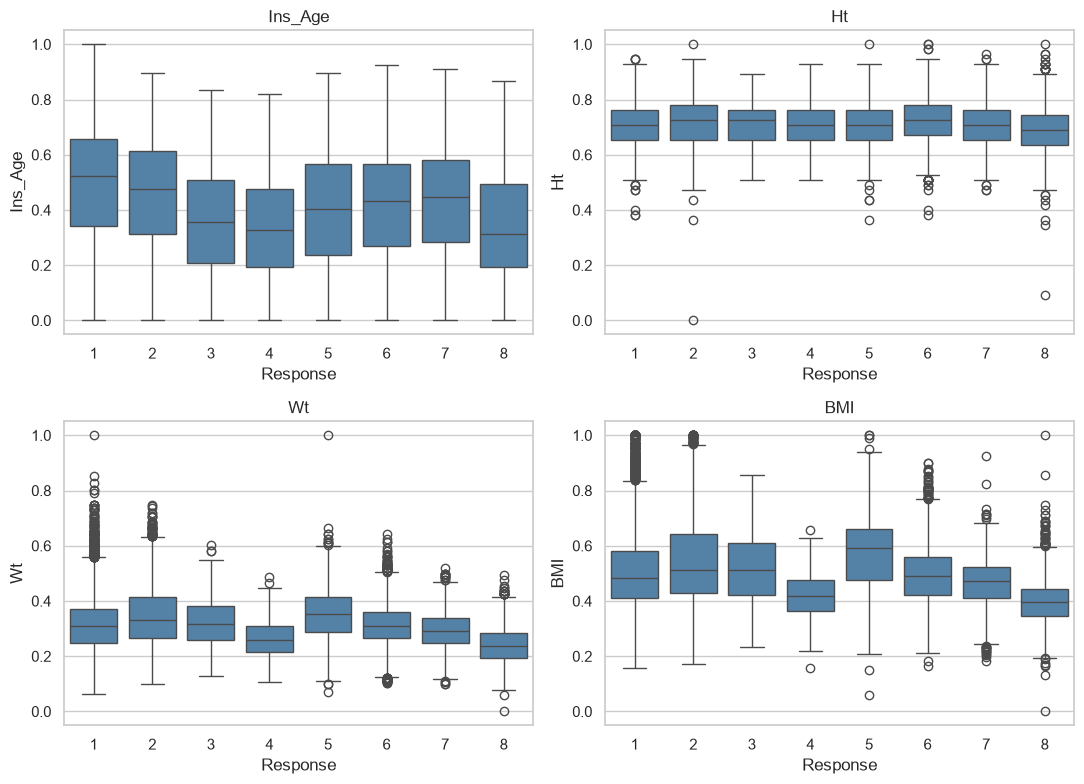

In [6]:

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), ["Ins_Age", "Ht", "Wt", "BMI"]):
    sns.boxplot(data=df, x="Response", y=col, ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()


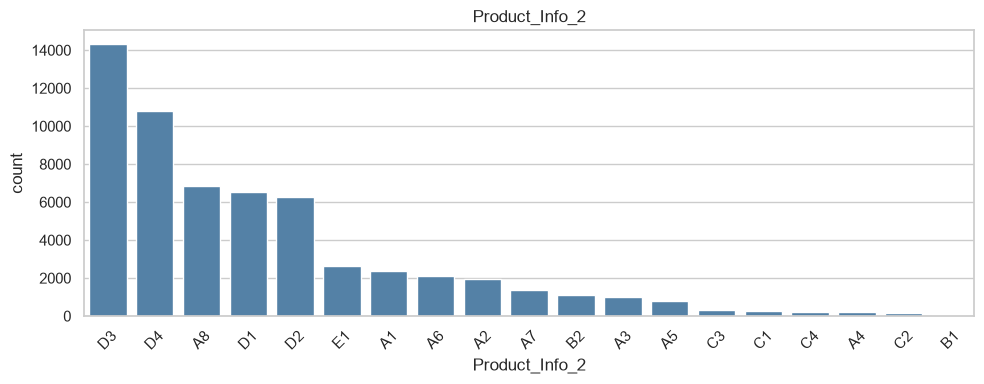

,mean,count
Product_Info_2,,
C3,5.611111,306
A3,6.003071,977
C4,6.118721,219
A1,6.129496,2363
E1,6.138270,2647
A4,6.371429,210
D4,6.387162,10812
B2,6.529412,1122
A5,6.627097,775


In [7]:

fig, ax = plt.subplots(figsize=(10, 4))
order = df["Product_Info_2"].value_counts().index
sns.countplot(data=df, x="Product_Info_2", order=order, ax=ax, color="steelblue")
ax.tick_params(axis="x", rotation=45)
ax.set_title("Product_Info_2")
plt.tight_layout()
plt.show()

prod_risk = df.groupby("Product_Info_2")["Response"].agg(["mean", "count"]).sort_values("mean")
display(prod_risk.tail(10))


,Family_Hist_1_miss,Family_Hist_2_miss,Family_Hist_3_miss,Family_Hist_4_miss,Family_Hist_5_miss
Response,,,,,
1,0.0,0.652328,0.436443,0.499275,0.543419
2,0.0,0.593864,0.473291,0.418803,0.613095
3,0.0,0.472853,0.603159,0.299112,0.735439
4,0.0,0.385854,0.679972,0.248599,0.783613
5,0.0,0.522828,0.563328,0.355118,0.681333
6,0.0,0.501024,0.549274,0.327517,0.697498
7,0.0,0.542419,0.507412,0.372991,0.650430
8,0.0,0.352199,0.695059,0.209400,0.810714


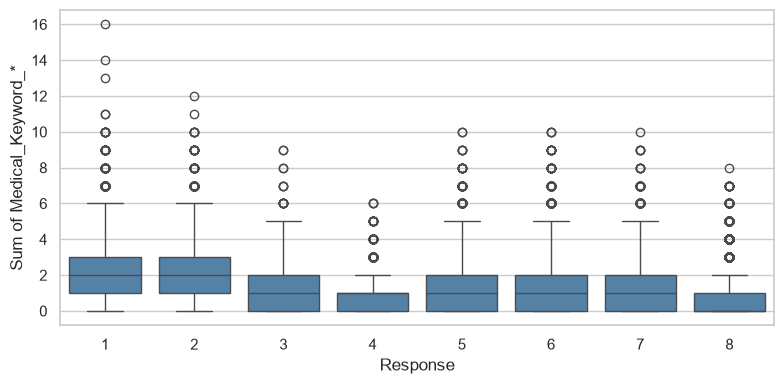

In [8]:

fam_cols = [c for c in df.columns if c.startswith("Family_Hist_")]
miss_by_resp = (
    df.assign(**{f"{c}_miss": df[c].isna() for c in fam_cols})
    .groupby("Response")[[f"{c}_miss" for c in fam_cols]]
    .mean()
)
display(miss_by_resp)

kw = [c for c in df.columns if c.startswith("Medical_Keyword_")]
plot_df = df.copy()
plot_df["keyword_count"] = plot_df[kw].sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=plot_df, x="Response", y="keyword_count", ax=ax, color="steelblue")
ax.set_ylabel("Sum of Medical_Keyword_*")
plt.tight_layout()
plt.show()


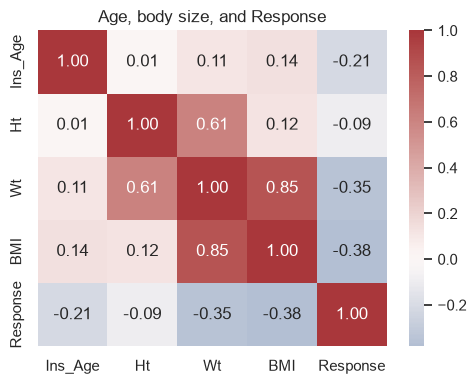

In [9]:

corr = df[["Ins_Age", "Ht", "Wt", "BMI", "Response"]].corr()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Age, body size, and Response")
plt.tight_layout()
plt.show()


## Save the split


In [10]:

print("Dropping:", DROP_SPARSE)
result = fit_save_artefacts()
for key, value in result["meta"].items():
    print(f"{key}: {value}")

X_train = result["X_train"]
pre = build_preprocessor(X_train, scale_numeric=False).fit(X_train)
print("X_train", X_train.shape, "X_test", result["X_test"].shape)
print("Transformed width:", np.asarray(pre.transform(X_train[:5])).shape[1])


Dropping: ['Medical_History_10', 'Medical_History_32', 'Medical_History_24', 'Medical_History_15']


n_rows: 59381
n_features: 134
train_rows: 47504
holdout_rows: 11877
response_counts: {1: 6207, 2: 6552, 3: 1013, 4: 1428, 5: 5432, 6: 11233, 7: 8027, 8: 19489}
train_response_counts: {1: 4966, 2: 5242, 3: 810, 4: 1142, 5: 4346, 6: 8986, 7: 6421, 8: 15591}
holdout_response_counts: {1: 1241, 2: 1310, 3: 203, 4: 286, 5: 1086, 6: 2247, 7: 1606, 8: 3898}
dropped_columns: ['Medical_History_10', 'Medical_History_32', 'Medical_History_24', 'Medical_History_15']
random_state: 42
test_size: 0.2


X_train (47504, 134) X_test (11877, 134)
Transformed width: 152
